# A multimodal ingestion pipeline with contracts

**Course** MLAIDP · **Module 2 — Advanced Data Processing for Foundation Models**
· **When:** after slide 27 (*Data validation and quality assurance best practices*), before slide 28 (*Input
optimization and performance enhancement*); §6 links forward to slides 31–33
· **Kernel** MLAIDP (Python 3.12) · your AWS credentials (`AWS_PROFILE` or the default chain), us-east-1
· **Runtime** about 30 seconds of cell time (the Transcribe jobs take 3–12 s) · **Cost per run** about $0.03
  (Transcribe ≈ 2 × 20 s of audio, ≈ 35 Nova calls, ≈ 15 Comprehend calls)

**What you'll learn**
- Turn a phone call into text with an **Amazon Transcribe** batch job — and measure what PII redaction removes: does
  the incident date survive "redact *every* type"?
- Protect personal data from the **text** sources **before** the model: Amazon Comprehend PII offsets → **reversible
  pseudonymization** with a vault, deny-by-default entity policy, and a code assertion that no raw value from the email
  or the call reaches Bedrock (the form *image* is not covered — see §3).
- Make extraction a **contract**: a JSON schema as a Converse **tool with forced `toolChoice`**, validated in code with
  `jsonschema`, a **repair turn** that sends the validation errors back, and lineage on every record.
- **Reconcile** three sources (form image, call, email) field by field and run a **data-quality gate** with DQDL-style
  rules over a batch: quarantine with reasons, not silent deletion.
- Measure the **token economics of images** and of the tool scaffold: what resolution and structured output cost per
  model.

> **Resources:** S3 bucket `mlaidp2-m02-<account>-us-east-1` (audio, transcripts, accepted/quarantined records) and two
> Transcribe jobs `mlaidp2-m02-call-*`. §0 takes a few seconds. The cleanup section deletes both.

## §0 Setup

In [1]:
import sys, io, json, re, time, hashlib, difflib, contextlib
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from datetime import date, datetime, timezone

sys.path.insert(0, "../common")
import mlaidp as m
import jsonschema
from botocore.exceptions import ClientError
from IPython.display import Audio, Image as ShowImage, display

RID = m.setup_banner("M02")
bedrock, comprehend, transcribe, s3 = (m.client(n) for n in ("bedrock-runtime", "comprehend", "transcribe", "s3"))

BUCKET = f"mlaidp2-m02-{m.account()}-{m.REGION}"
AUDIO_FILE = m.ASSETS / "claim_call_AC-77812-H.mp3"
AUDIO_KEY = "m02/input/claim_call_AC-77812-H.mp3"
FORM_FILE = m.ASSETS / "claim_form_1000px.png"
EXTRACTOR = m.NOVA_LITE            # reads images and follows a forced tool choice; cheapest Nova that does both well

account 1143…  ·  us-east-1  ·  credentials AWS_PROFILE  ·  run id 1022b42a


### §0 Prep — the landing bucket (idempotent: adopt or create)
Private by default (public access block), encrypted at rest (SSE-S3 is the S3 default), and a lifecycle rule so raw
inputs do not outlive their purpose — retention is a data-protection control, not housekeeping.

In [2]:
def ensure_bucket(name: str) -> None:
    try:
        s3.head_bucket(Bucket=name)
        print(f"adopted bucket {m.masked(name)}")
    except ClientError:
        s3.create_bucket(Bucket=name)          # us-east-1: no LocationConstraint
        s3.get_waiter("bucket_exists").wait(Bucket=name)
        print(f"created bucket {m.masked(name)}")
    s3.put_bucket_tagging(Bucket=name, Tagging={"TagSet": [{"Key": k, "Value": v} for k, v in m.TAGS.items()]})
    s3.put_public_access_block(Bucket=name, PublicAccessBlockConfiguration={
        "BlockPublicAcls": True, "IgnorePublicAcls": True, "BlockPublicPolicy": True, "RestrictPublicBuckets": True})
    s3.put_bucket_lifecycle_configuration(Bucket=name, LifecycleConfiguration={"Rules": [
        {"ID": "expire-raw-inputs", "Status": "Enabled", "Filter": {"Prefix": "m02/"}, "Expiration": {"Days": 7}}]})

ensure_bucket(BUCKET)
s3.upload_file(str(AUDIO_FILE), BUCKET, AUDIO_KEY)
print(f"uploaded s3://{m.masked(BUCKET)}/{AUDIO_KEY}  ({AUDIO_FILE.stat().st_size // 1024} KB)")

created bucket mlaidp2-m02-123456789012-us-east-1


uploaded s3://mlaidp2-m02-123456789012-us-east-1/m02/input/claim_call_AC-77812-H.mp3  (130 KB)


## 1 · One claim, three modalities
Dana Ruiz reports a broken window three ways: a **scanned form**, a **phone call** and an **email**. The pipeline
must turn all three into one standardized claim record (slide 25) — and notice when they do not agree.

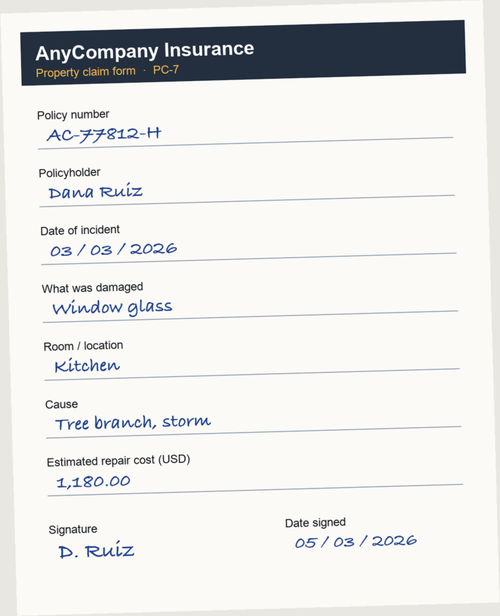

From: dana.ruiz@example.com
Sent: 2026-03-05
Subject: Claim - broken kitchen window

Hello, following up on my call. Policy AC-77812-H. On 3 March 2026 a tree branch went through our kitchen window
during the storm. The glazier quoted 1,180 USD. Photos attached. You can reach me on 555-0142 or at
14 Elm Street, Springfield. Dana Ruiz


In [3]:
EMAIL = """From: dana.ruiz@example.com
Sent: 2026-03-05
Subject: Claim - broken kitchen window

Hello, following up on my call. Policy AC-77812-H. On 3 March 2026 a tree branch went through our kitchen window
during the storm. The glazier quoted 1,180 USD. Photos attached. You can reach me on 555-0142 or at
14 Elm Street, Springfield. Dana Ruiz"""

display(ShowImage(filename=str(m.ASSETS / "claim_form_500px.png"), width=330))
display(Audio(filename=str(AUDIO_FILE)))
print(EMAIL)

### Audio → text: Amazon Transcribe batch job, with PII redaction
Two jobs on the same recording, in parallel: one redacts **every** PII type, one only the types we must remove
(`PiiEntityTypes`). Output goes to our own bucket (`OutputBucketName`) — the transcript is data we govern, not a
pre-signed link that expires.

In [4]:
MUST_REDACT = ["NAME", "PHONE", "EMAIL", "SSN", "ADDRESS", "CREDIT_DEBIT_NUMBER", "BANK_ACCOUNT_NUMBER"]

def job_state(j: dict):
    if j["TranscriptionJobStatus"] == "FAILED":
        raise RuntimeError(j.get("FailureReason"))
    return True if j["TranscriptionJobStatus"] == "COMPLETED" else j["TranscriptionJobStatus"]

def transcribe_call(variant: str, pii_types: list | None) -> dict:
    job = f"mlaidp2-m02-call-{variant}-{RID}"
    try:                                   # job names are unique: re-running the notebook replaces the job
        transcribe.delete_transcription_job(TranscriptionJobName=job)
    except ClientError:
        pass
    redaction = {"RedactionType": "PII", "RedactionOutput": "redacted",
                 **({"PiiEntityTypes": pii_types} if pii_types else {})}
    t0 = time.time()
    transcribe.start_transcription_job(
        TranscriptionJobName=job, LanguageCode="en-US", MediaFormat="mp3",
        Media={"MediaFileUri": f"s3://{BUCKET}/{AUDIO_KEY}"},
        OutputBucketName=BUCKET, OutputKey=f"m02/transcripts/{job}.json",
        ContentRedaction=redaction, Tags=[{"Key": k, "Value": v} for k, v in m.TAGS.items()])
    j = m.wait_for(lambda: transcribe.get_transcription_job(TranscriptionJobName=job)["TranscriptionJob"],
                   until=job_state, timeout=300, every=2, label=f"job {variant}")
    key = j["Transcript"]["RedactedTranscriptFileUri"].split(f"{BUCKET}/", 1)[1]
    data = json.loads(s3.get_object(Bucket=BUCKET, Key=key)["Body"].read())
    return {"variant": variant, "job": job, "seconds": round(time.time() - t0, 1),
            "text": data["results"]["transcripts"][0]["transcript"], "items": data["results"]["items"]}

with ThreadPoolExecutor(2) as pool:
    redact_all, redact_must = pool.map(lambda a: transcribe_call(*a), [("all", None), ("must", MUST_REDACT)])
for t in (redact_all, redact_must):
    print(f"\n[{t['variant']}, {t['seconds']} s] {t['text']}")

  job must IN_PROGRESS (0 s)
  job all IN_PROGRESS (0 s)


  job all ready after 10 s


  job must ready after 14 s

[all, 11.4 s] Hi, my name is [PII]. I'm calling about my home insurance. The policy number is AC 77812H. On the [PII], a big branch came down in the storm and smashed our living room window. My phone number is [PII]. The repair will be around $1100. Thank you.

[must, 15.5 s] Hi, my name is [PII]. I'm calling about my home insurance. The policy number is AC 77812H. On the 4th of March, a big branch came down in the storm and smashed our living room window. My phone number is [PII]. The repair will be around $1100. Thank you.


What did "redact everything" cost us? Diff the two transcripts word by word.

In [5]:
a, b = redact_must["text"].split(), redact_all["text"].split()
lost = [" ".join(a[i1:i2]) for op, i1, i2, _, _ in difflib.SequenceMatcher(None, a, b).get_opcodes() if op != "equal"]
print("removed only by 'redact all':", lost)
print("✓ the incident date survives in the scoped job, not in 'redact all'"
      if re.search(r"March", redact_must["text"]) and not re.search(r"March", redact_all["text"]) else
      "✗ both transcripts treat the date the same way - read them above")

removed only by 'redact all': ['4th of March,']
✓ the incident date survives in the scoped job, not in 'redact all'


**Confidence scores** (slide 27): every recognized word has one. Map the words that carry each claim field to their
confidence; a field whose evidence is below the threshold goes to a person, whatever the model later makes of it.

In [6]:
EVIDENCE = {"policy_number": r"^(AC|77812H)$", "incident_date": r"^(4th|March)$", "room": r"^(living|room)$",
            "amount_usd": r"^\$?1,?100$"}
CONFIDENCE_FLOOR = 0.90

words = [(i["alternatives"][0]["content"], float(i["alternatives"][0]["confidence"]))
         for i in redact_must["items"] if i["type"] == "pronunciation" and i["alternatives"][0].get("confidence")]
FIELD_CONFIDENCE = {}
for field, pattern in EVIDENCE.items():
    hits = [(w, c) for w, c in words if re.match(pattern, w)]
    FIELD_CONFIDENCE[field] = min((c for _, c in hits), default=None)
    print(f"{field:14s} evidence {[w for w, _ in hits]!s:28s} min confidence {FIELD_CONFIDENCE[field]}"
          f"  {'✓' if (FIELD_CONFIDENCE[field] or 0) >= CONFIDENCE_FLOOR else '✗ → human review'}")
print(f"lowest word in the call: {min(words, key=lambda x: x[1])}")

policy_number  evidence ['AC', '77812H']             min confidence 0.994  ✓
incident_date  evidence ['4th', 'March']             min confidence 0.993  ✓
room           evidence ['living', 'room']           min confidence 0.972  ✓
amount_usd     evidence ['$1100']                    min confidence 0.979  ✓
lowest word in the call: ('policy', 0.965)


> **Think about it:** Did "redact all PII" cost us a field the claim needs? Who in your organization decides which
> entity types are *must redact* — and where is that list versioned?

<details><summary>More questions</summary>

- The job wrote the transcript to our bucket. Should the *unredacted* transcript exist at all (`RedactionOutput`)?
- When would you use streaming transcription instead of a batch job (slide 26)?
</details>

## 2 · Personal data from the text sources never reaches the model
Amazon Comprehend returns PII **offsets**, not strings (slide 12's `entity['Text']` does not exist in the response).
Policy: **deny by default** — every detected type is replaced unless the task needs it. Replacement is **reversible
pseudonymization**: `[NAME_1]` goes to the model, the real value stays in a vault in our code.

First, what does a detector think our *business keys* are? Three lines from this morning's inbox:

In [7]:
for line in ["Policy no. is hp 4410. Hail hit the roof two days before 1 May 2026.",
             "HP-2291 here. The storm on 12 November 2026 broke our bedroom window.",
             "Resending: policy AC-77812-H, 3 March 2026, kitchen window, 1,180 USD."]:
    found = comprehend.detect_pii_entities(Text=line, LanguageCode="en")["Entities"]
    print(f"{line[:48]:50s}", [(e["Type"], round(e["Score"], 2), line[e["BeginOffset"]:e["EndOffset"]]) for e in found])

Policy no. is hp 4410. Hail hit the roof two day   [('LICENSE_PLATE', 0.82, 'hp 4410'), ('NAME', 0.93, 'Hail'), ('DATE_TIME', 1.0, '1'), ('DATE_TIME', 1.0, 'May 2026')]
HP-2291 here. The storm on 12 November 2026 brok   [('LICENSE_PLATE', 0.92, 'HP-2291'), ('DATE_TIME', 1.0, '12 November 2026')]


Resending: policy AC-77812-H, 3 March 2026, kitc   [('UK_NATIONAL_INSURANCE_NUMBER', 0.4, 'AC-77812-H'), ('DATE_TIME', 1.0, '3'), ('DATE_TIME', 1.0, 'March 2026')]


Read the types the detector gave our policy numbers (and the word "Hail") above. If a policy number shows up as PII
with a score over the threshold, deny-by-default would erase the one field the claim cannot do without — and the
scores can change from run to run. So the policy has two exceptions, both explicit and versioned with the code:
entity **types** the task needs (`KEEP_TYPES`) and **values** that match our own identifier formats (`BUSINESS_KEYS`).

In [8]:
KEEP_TYPES = {"DATE_TIME"}                                         # the claim needs dates
BUSINESS_KEYS = re.compile(r"^[A-Za-z]{2}[- ]?\d{4,5}(-?[A-Za-z])?$")  # our policy-number format: a business key, not PII
PII_THRESHOLD = 0.5                    # low on purpose: a false redaction costs less than a leak

def pseudonymize(text: str) -> tuple[str, dict, list]:
    found = comprehend.detect_pii_entities(Text=text, LanguageCode="en")["Entities"]
    vault, n = {}, Counter()
    for e in sorted(found, key=lambda e: e["BeginOffset"]):          # decide and number tokens left to right ...
        b, end = e["BeginOffset"], e["EndOffset"]
        value = text[b:end]
        e["action"] = ("kept: type needed" if e["Type"] in KEEP_TYPES
                       else "kept: business key" if BUSINESS_KEYS.match(value)
                       else "kept: already a placeholder" if text[b - 1:b] == "[" and text[end:end + 1] == "]"
                       else "kept: low score" if e["Score"] < PII_THRESHOLD else None)
        if e["action"]:
            continue
        token = next((t for t, v in vault.items() if v == value), None)
        if not token:
            n[e["Type"]] += 1
            token = f"[{e['Type']}_{n[e['Type']]}]"
            vault[token] = value
        e["action"] = token
    for e in sorted(found, key=lambda e: e["BeginOffset"], reverse=True):  # ... replace right to left: offsets stay valid
        if e["action"].startswith("["):
            text = text[:e["BeginOffset"]] + e["action"] + text[e["EndOffset"]:]
    return text, vault, found

The vault maps each placeholder back to its value; `detokenize` is the privileged way back.

In [9]:
def detokenize(value, vault: dict):
    if not isinstance(value, str):
        return value
    return re.sub(r"\[[A-Z_]+_\d+\]", lambda t: vault.get(t.group(0), t.group(0)), value)

EMAIL_SAFE, EMAIL_VAULT, email_entities = pseudonymize(EMAIL)
m.table([[e["Type"], f"{e['Score']:.3f}",
          EMAIL[e["BeginOffset"]:e["EndOffset"]] if e["action"].startswith("kept") else "•••", e["action"]]
         for e in email_entities], ["Type", "Score", "Value", "Action"])
print(EMAIL_SAFE)

Type,Score,Value,Action
EMAIL,1.000,•••,[EMAIL_1]
DATE_TIME,1.000,2026-03-05,kept: type needed
DATE_TIME,1.000,3,kept: type needed
DATE_TIME,1.000,March 2026,kept: type needed
PHONE,0.999,•••,[PHONE_1]
ADDRESS,0.999,•••,[ADDRESS_1]
NAME,0.999,•••,[NAME_1]


From: [EMAIL_1]
Sent: 2026-03-05
Subject: Claim - broken kitchen window

Hello, following up on my call. Policy AC-77812-H. On 3 March 2026 a tree branch went through our kitchen window
during the storm. The glazier quoted 1,180 USD. Photos attached. You can reach me on [PHONE_1] or at
[ADDRESS_1]. [NAME_1]


The transcript was already redacted by Transcribe — run it through the same policy anyway (defense in depth: two
detectors miss different things). Then **assert** in code that no vault value is in any *text* we send to Bedrock.
(The form image is a different problem: Comprehend reads text, not pixels — see §3.)

In [10]:
CALL_SAFE, CALL_VAULT, _ = pseudonymize(redact_must["text"])
model_inputs = [EMAIL_SAFE, CALL_SAFE]
leaks = [v for vault in (EMAIL_VAULT, CALL_VAULT) for v in vault.values() for text in model_inputs if v in text]
print(CALL_SAFE)
print(f"vaults hold {len(EMAIL_VAULT) + len(CALL_VAULT)} values; "
      + ("✓ no raw PII value in any text model input" if not leaks else f"✗ LEAK: {leaks}"))

Hi, my name is [PII]. I'm calling about my home insurance. The policy number is AC 77812H. On the 4th of March, a big branch came down in the storm and smashed our living room window. My phone number is [PII]. The repair will be around $1100. Thank you.
vaults hold 4 values; ✓ no raw PII value in any text model input


> **Think about it:** The vault makes redaction reversible. Where must the vault live in production — and who may
> call `detokenize`?

<details><summary>More questions</summary>

- Masking, tokenization, removal (slide 12): which one keeps the model's extraction quality, and which one is
  GDPR-erasable?
- The threshold is 0.5. What does the precision/recall trade-off look like for a support chatbot vs a claims archive?
</details>

## 3 · Extraction as a contract
The schema is the contract between the model and the rest of the system: types, a canonical policy-number pattern,
an ISO date, an enum for the room, explicit `UNKNOWN` sentinels instead of guesses. It goes to the model as a **tool**,
and `toolChoice` forces the model to call it — Nova rejects Converse's `outputConfig` JSON schema, tool use works.

In [11]:
CLAIM_SCHEMA = {
    "type": "object",
    "required": ["policy_number", "incident_date", "damaged_item", "room", "amount_usd", "claimant"],
    "properties": {
        "policy_number": {"type": "string", "pattern": r"^([A-Z]{2}-\d{4,5}(-[A-Z])?|UNKNOWN)$",
                          "description": "Canonical form, upper case with hyphens, e.g. AC-12345-H or HP-2291. "
                                         "UNKNOWN if not stated."},
        "incident_date": {"type": "string", "pattern": r"^(\d{4}-\d{2}-\d{2}|UNKNOWN)$",
                          "description": "Date of the incident, YYYY-MM-DD. UNKNOWN if not stated."},
        "damaged_item": {"type": "string", "description": "What was damaged, 1-3 words, lower case."},
        "room": {"type": "string", "enum": ["kitchen", "living room", "bedroom", "bathroom", "basement", "roof",
                                            "garage", "vehicle", "other", "unknown"]},
        "amount_usd": {"type": "number", "minimum": 0,
                       "description": "Claimed or estimated amount in USD; 0 if not stated."},
        "claimant": {"type": "string",
                     "description": "Claimant name or its placeholder token exactly as written, e.g. [NAME_1]."},
    },
}
SCHEMA_ID = "claim-v1/" + hashlib.sha256(json.dumps(CLAIM_SCHEMA, sort_keys=True).encode()).hexdigest()[:8]
VALIDATOR = jsonschema.Draft202012Validator(CLAIM_SCHEMA)
TOOL = {"toolSpec": {"name": "record_claim", "description": "Record the insurance claim described in the source.",
                     "inputSchema": {"json": CLAIM_SCHEMA}}}

def violations(record: dict) -> list[str]:
    return [f"{'.'.join(map(str, e.path)) or 'record'}: {e.message}" for e in VALIDATOR.iter_errors(record)]

print(SCHEMA_ID)
print("a plausible-looking bad record ->", violations({"policy_number": "AC 77812H", "incident_date": "03/03/2026",
                                                       "room": "Kitchen", "amount_usd": "1,180", "claimant": "[NAME_1]"}))

claim-v1/3b2c8718
a plausible-looking bad record -> ["record: 'damaged_item' is a required property", "policy_number: 'AC 77812H' does not match '^([A-Z]{2}-\\\\d{4,5}(-[A-Z])?|UNKNOWN)$'", "incident_date: '03/03/2026' does not match '^(\\\\d{4}-\\\\d{2}-\\\\d{2}|UNKNOWN)$'", "room: 'Kitchen' is not one of ['kitchen', 'living room', 'bedroom', 'bathroom', 'basement', 'roof', 'garage', 'vehicle', 'other', 'unknown']", "amount_usd: '1,180' is not of type 'number'"]


`extract()` is the whole pattern: forced tool call → validate in code → if invalid, send the errors back as a failed
**toolResult** (the model sees exactly what broke) → at most three attempts → every record carries its **lineage**
(schema id, model, prompt hash, attempts) for audit (slide 13).

In [12]:
INSTRUCTIONS = ("Extract the insurance claim from this {source}. Copy placeholder tokens such as [NAME_1] unchanged. "
                "If a date has no year, the year is 2026.")

def extract(source: str, content: list, model: str = EXTRACTOR, attempts: int = 3) -> dict:
    prompt = INSTRUCTIONS.format(source=source)
    messages = [{"role": "user", "content": content + [{"text": prompt}]}]
    usage, repairs, t0 = Counter(), [], time.perf_counter()
    for attempt in range(1, attempts + 1):
        r = bedrock.converse(modelId=model, messages=messages,
                             inferenceConfig={"maxTokens": 500, "temperature": 0},
                             toolConfig={"tools": [TOOL], "toolChoice": {"tool": {"name": "record_claim"}}})
        usage.update({k: v for k, v in r["usage"].items() if isinstance(v, int)})
        call = next(c["toolUse"] for c in r["output"]["message"]["content"] if "toolUse" in c)
        errors = violations(call["input"])
        if not errors:
            break
        repairs.append(errors)
        messages += [r["output"]["message"], {"role": "user", "content": [{"toolResult": {
            "toolUseId": call["toolUseId"], "status": "error", "content": [{"text": "Rejected by schema validation: "
            + "; ".join(errors) + ". Call record_claim again with corrected values."}]}}]}]
    lineage = {"schema": SCHEMA_ID, "model": model, "prompt_sha": hashlib.sha256(prompt.encode()).hexdigest()[:8],
               "at": datetime.now(timezone.utc).isoformat(timespec="seconds")}
    return {"source": source, "fields": call["input"], "valid": not errors, "attempts": attempt, "repairs": repairs,
            "usage": dict(usage), "usd": m.usd(model, usage), "ms": (time.perf_counter() - t0) * 1000,
            "lineage": lineage}

Three branches in parallel (a Step Functions **Parallel** state in production, slide 24): the two texts go in
**pseudonymized**, the image goes in as raw bytes — **unredacted**. Look at the form's `claimant` column: whatever
name is printed on the form reaches the model. Comprehend reads text, not pixels; protecting an image needs OCR with
bounding boxes (Amazon Textract) and pixel redaction before the model, or Amazon Bedrock Data Automation.

In [13]:
BRANCHES = {
    "form (image)": lambda: extract("scanned claim form",
                                    [{"image": {"format": "png", "source": {"bytes": FORM_FILE.read_bytes()}}}]),
    "email (text)": lambda: extract("customer email", [{"text": EMAIL_SAFE}]),
    "call (audio)": lambda: extract("phone call transcript", [{"text": CALL_SAFE}]),
}
t0 = time.time()
with ThreadPoolExecutor(3) as pool:
    EXTRACTED = dict(zip(BRANCHES, pool.map(lambda f: f(), BRANCHES.values())))
wall = time.time() - t0
m.table([{"source": s, **r["fields"], "valid": "✓" if r["valid"] else "✗", "attempts": r["attempts"],
          "in tok": r["usage"]["inputTokens"], "ms": r["ms"]} for s, r in EXTRACTED.items()], fmt={"ms": "{:.0f}"})
print(f"wall clock {wall:.1f} s vs sum of branches {sum(r['ms'] for r in EXTRACTED.values()) / 1000:.1f} s"
      f"  ·  lineage: {EXTRACTED['form (image)']['lineage']}")
for s, r in EXTRACTED.items():
    for i, errs in enumerate(r["repairs"], 1):
        print(f"  repair turn {i} for {s}: {errs}")

source,damaged_item,policy_number,incident_date,amount_usd,claimant,room,valid,attempts,in tok,ms
form (image),window glass,AC-77812-H,2026-03-03,1180,Dana Ruiz,kitchen,✓,1,2280,1793
email (text),kitchen window,AC-77812-H,2026-03-03,1180,[NAME_1],kitchen,✓,2,1810,1826
call (audio),window,AC-77812-H,2026-03-04,1100,[PII],living room,✓,2,1784,1758


wall clock 1.8 s vs sum of branches 5.4 s  ·  lineage: {'schema': 'claim-v1/3b2c8718', 'model': 'us.amazon.nova-lite-v1:0', 'prompt_sha': '38975ee7', 'at': '2026-10-22T16:58:44+00:00'}
  repair turn 1 for email (text): ["record: 'room' is a required property"]
  repair turn 1 for call (audio): ["policy_number: 'AC-77812H' does not match '^([A-Z]{2}-\\\\d{4,5}(-[A-Z])?|UNKNOWN)$'"]


> **Think about it:** The schema says *what shape*; nothing yet says *whether it is true*. Which of these fields
> could pass validation and still be wrong?

<details><summary>More questions</summary>

- Why `UNKNOWN` sentinels instead of nullable fields? (Hint: what does a model do with an optional field it cannot
  fill?)
- When should a repair loop give up and route to a human instead of a stronger model?
</details>

## 4 · Reconciliation at the sync point
The sync point (slide 24) is ordinary code: normalize each field, compare across sources with a rule per field, and
decide. **Material** fields that disagree send the claim to a person; others are resolved by source precedence (the
signed form wins) and flagged. Low transcription confidence on a field counts as a disagreement.

In [14]:
FIELD_RULES = {"policy_number": "equal after normalization", "incident_date": "equal", "room": "equal",
               "damaged_item": "same category", "amount_usd": "within 10 %"}
MATERIAL = {"policy_number", "incident_date", "amount_usd"}
PRECEDENCE = ["form (image)", "email (text)", "call (audio)"]

def norm(field: str, v):
    if v in (None, "", "UNKNOWN", "unknown", 0):
        return None
    if field == "policy_number":
        return re.sub(r"[^A-Z0-9]", "", str(v).upper())
    if field == "damaged_item":
        return "window" if re.search(r"window|glass|glaz|pane", str(v), re.I) else str(v).lower()
    return v if field == "amount_usd" else str(v).strip().lower()

def agree(field: str, values: list) -> bool:
    if field == "amount_usd":
        return max(values) - min(values) <= 0.10 * max(values)
    return len(set(values)) == 1

RECORD, ROWS, REASONS = {}, [], []
for field in FIELD_RULES:
    vals = {s: EXTRACTED[s]["fields"].get(field) for s in PRECEDENCE}
    present = [norm(field, v) for v in vals.values() if norm(field, v) is not None]
    ok = bool(present) and agree(field, present)
    low_conf = (FIELD_CONFIDENCE.get(field) or 1) < CONFIDENCE_FLOOR
    RECORD[field] = next(v for s, v in vals.items() if norm(field, v) is not None) if present else None
    if not ok or low_conf:
        REASONS.append(f"{field} {'disagrees' if not ok else 'low confidence'}"
                       + (" (material)" if field in MATERIAL else ""))
    ROWS.append({"field": field, **vals, "rule": FIELD_RULES[field], "verdict": "✓ agree" if ok else "✗ DISAGREE",
                 "resolved": RECORD[field]})
m.table(ROWS)

field,form (image),email (text),call (audio),rule,verdict,resolved
policy_number,AC-77812-H,AC-77812-H,AC-77812-H,equal after normalization,✓ agree,AC-77812-H
incident_date,2026-03-03,2026-03-03,2026-03-04,equal,✗ DISAGREE,2026-03-03
room,kitchen,kitchen,living room,equal,✗ DISAGREE,kitchen
damaged_item,window glass,kitchen window,window,same category,✓ agree,window glass
amount_usd,1180,1180,1100,within 10 %,✓ agree,1180


In [15]:
route = "HUMAN_REVIEW" if any("(material)" in r for r in REASONS) else "AUTOMATED"
RECORD |= {"claimant": detokenize(EXTRACTED["email (text)"]["fields"].get("claimant"), EMAIL_VAULT),
           "route": route, "reasons": REASONS, "sources": {s: r["lineage"] for s, r in EXTRACTED.items()}}
print(json.dumps({k: v for k, v in RECORD.items() if k != "sources"}, indent=1))
planted = {"incident_date", "room"}    # the call says 4 March, living room; form and email say 3 March, kitchen
caught = {r.split()[0] for r in REASONS}
print(f"✓ both planted conflicts caught, claim routed to {route}" if planted <= caught and route == "HUMAN_REVIEW"
      else f"✗ caught {caught or 'nothing'}, route {route} - read the table")

{
 "policy_number": "AC-77812-H",
 "incident_date": "2026-03-03",
 "room": "kitchen",
 "damaged_item": "window glass",
 "amount_usd": 1180,
 "claimant": "Dana Ruiz",
 "route": "HUMAN_REVIEW",
 "reasons": [
  "incident_date disagrees (material)",
  "room disagrees"
 ]
}
✓ both planted conflicts caught, claim routed to HUMAN_REVIEW


> **Think about it:** The signed form says 3 March, the call says 4 March. Should a model be allowed to pick one?
> What would you log so an auditor can see *why* the claim went to a person?

<details><summary>More questions</summary>

- How far apart are the three amounts — and do they still "agree" under the 10 % rule? Who sets that tolerance, and
  per what?
- Which branch dominates the wall clock — and what does that say about where to spend optimization effort?
</details>

## 5 · A data-quality gate with a quarantine
Ten claim emails from one morning's inbox go through the same pipeline: pseudonymize → extract under the contract →
**rules**. The rules are written the way you would write them in an **AWS Glue Data Quality** ruleset (DQDL, slide 8)
plus domain rules from a policy register (slide 9). Nothing is deleted: failing records go to a quarantine prefix
with their reasons and lineage.

In [16]:
POLICIES = {  # the policy register the domain rules check against
    "AC-77812-H": {"status": "ACTIVE", "start": "2025-06-01", "end": "2026-05-31", "limit": 50_000},
    "HP-2291": {"status": "ACTIVE", "start": "2026-01-01", "end": "2026-12-31", "limit": 75_000},
    "HP-4410": {"status": "ACTIVE", "start": "2026-01-01", "end": "2026-12-31", "limit": 75_000},
    "AU-0912": {"status": "LAPSED", "start": "2025-02-01", "end": "2026-01-31", "limit": 30_000},
}
INBOX = [  # (id, sent, body) - the problems are planted, the EXPECTED column says which rule should catch them
    ("E01", "2026-03-05", EMAIL.split("\n\n", 1)[1]),
    ("E02", "2026-09-14", "Hi, a delivery truck dented my garage door yesterday, about 900 dollars to fix. Sam Lee, "
                          "sam.lee@example.com"),
    ("E03", "2026-05-02", "Policy no. is hp 4410. Hail hit the roof two days before 1 May 2026, the roofer quotes "
                          "6,400 USD. Card for the deductible: 4111 1111 1111 1111. Ana Silva"),
    ("E04", "2026-09-22", "Policy AU-0912. Someone hit my car in the parking lot on 2026-09-20, the body shop quotes "
                          "2,300 USD. Tom Becker"),
    ("E05", "2026-10-02", "HP-2291 here. The storm on 12 November 2026 broke our bedroom window, repair 640 USD. Li Wei"),
    ("E06", "2026-10-02", "Policy HP-2291: a burst pipe flooded the bathroom on 2026-08-20. Plumber and new floor: "
                          "3,450 USD. Li Wei"),
    ("E07", "2026-09-30", "HP-2291 - fire in the kitchen on 2026-09-28, total loss of the house, estimate 1,250,000 USD. "
                          "Li Wei"),
    ("E08", "2026-03-06", "Resending in case you did not get it: policy AC-77812-H, 3 March 2026, kitchen window, "
                          "1,180 USD. Dana Ruiz"),
    ("E09", "2026-09-29", "Basement flooded from a burst pipe on 2026-09-28, 2,750 USD, policy HP-2291. "
                          "My SSN is 123-45-6789 "
                          "and the payout account is 000123456789. Maria Lopez, +1 555 0199"),
    ("E10", "2026-10-03", "You charged my card twice in October for policy HP-2291. Please refund the second "
                          "payment. Li Wei"),
]
EXPECTED = {"E01": None, "E02": "IsComplete policy_number", "E03": None, "E04": "WithinPolicyPeriod",
            "E05": "NotInFuture", "E06": "ReportedWithin 30 days", "E07": "ColumnValues amount_usd <= limit",
            "E08": "IsUnique claim", "E09": None, "E10": "ColumnValues amount_usd > 0"}

In [17]:
def d(s: str) -> date | None:
    return date.fromisoformat(s) if re.match(r"^\d{4}-\d{2}-\d{2}$", str(s)) else None

def in_period(r: dict) -> bool:
    pol, when = POLICIES.get(r["policy_number"]), d(r["incident_date"])
    return not pol or not when or d(pol["start"]) <= when <= d(pol["end"])

RULES = [  # (name as you would write it in DQDL / a custom rule, check(record, context) -> bool)
    ("Contract (schema valid)",          lambda r, c: r["valid"]),
    ("IsComplete policy_number",         lambda r, c: r["policy_number"] != "UNKNOWN"),
    ("IsComplete incident_date",         lambda r, c: d(r["incident_date"]) is not None),
    ("ColumnValues amount_usd > 0",      lambda r, c: r["amount_usd"] > 0),
    ("ReferentialIntegrity policy",      lambda r, c: r["policy_number"] in POLICIES),
    ("WithinPolicyPeriod",               lambda r, c: in_period(r)),
    ("NotInFuture",                      lambda r, c: not d(r["incident_date"]) or d(r["incident_date"]) <= d(r["sent"])),
    ("ReportedWithin 30 days",           lambda r, c: not d(r["incident_date"])
                                         or (d(r["sent"]) - d(r["incident_date"])).days <= 30),
    ("ColumnValues amount_usd <= limit", lambda r, c: r["amount_usd"]
                                         <= POLICIES.get(r["policy_number"], {"limit": 1e12})["limit"]),
    ("IsUnique claim",                   lambda r, c: c["first_seen"][r["key"]] == r["id"]),
]

`ingest()` is the per-email pipeline: pseudonymize → extract under the contract → a record the gate can always read.

In [18]:
MISSING = {"policy_number": "UNKNOWN", "incident_date": "UNKNOWN", "amount_usd": 0, "claimant": "UNKNOWN"}

def ingest(item) -> dict:
    eid, sent, body = item
    safe, vault, _ = pseudonymize(body)
    x = extract("customer email", [{"text": f"Sent: {sent}\n\n{safe}"}])     # the sent date resolves "yesterday"
    f = {**MISSING, **x["fields"]}       # an invalid record may lack fields: the gate must still be able to read it
    if not isinstance(f["amount_usd"], (int, float)):
        f["amount_usd"] = 0
    return {"id": eid, "sent": sent, **f, "claimant": detokenize(f.get("claimant"), vault), "valid": x["valid"],
            "attempts": x["attempts"], "pii_replaced": len(vault), "no_leak": not any(v in safe for v in vault.values()),
            "usd": x["usd"], "lineage": x["lineage"],
            "key": (re.sub(r"[^A-Z0-9]", "", str(f["policy_number"])), f["incident_date"], f["amount_usd"])}

t0 = time.time()
with ThreadPoolExecutor(4) as pool:
    BATCH = list(pool.map(ingest, INBOX))
print(f"{len(BATCH)} emails pseudonymized + extracted in {time.time() - t0:.1f} s, ${sum(r['usd'] for r in BATCH):.5f}")

10 emails pseudonymized + extracted in 3.6 s, $0.00070


In [19]:
for prefix in ("m02/accept/", "m02/quarantine/"):        # a re-run is a new batch: clear the previous decisions
    old = [{"Key": o["Key"]} for o in s3.list_objects_v2(Bucket=BUCKET, Prefix=prefix).get("Contents", [])]
    if old:
        s3.delete_objects(Bucket=BUCKET, Delete={"Objects": old})
ctx = {"first_seen": {}}
for r in sorted(BATCH, key=lambda r: r["sent"]):          # the first claim with a key wins, later copies are duplicates
    ctx["first_seen"].setdefault(r["key"], r["id"])
checks = 0
for r in BATCH:
    r["failed"] = [name for name, rule in RULES if not rule(r, ctx)]
    checks += len(RULES)
    r["decision"] = "QUARANTINE" if r["failed"] else "ACCEPT"
    s3.put_object(Bucket=BUCKET, Key=f"m02/{r['decision'].lower()}/{r['id']}.json", ContentType="application/json",
                  Body=json.dumps({k: v for k, v in r.items() if k != "key"}, default=str).encode())
m.table([{k: r[k] for k in ("id", "policy_number", "incident_date", "amount_usd", "claimant", "pii_replaced",
                            "attempts", "decision")} | {"failed rules": "; ".join(r["failed"]) or "–"} for r in BATCH],
        fmt={"amount_usd": "{:,.0f}"})
score = 1 - sum(len(r["failed"]) for r in BATCH) / checks
as_planted = [r["id"] for r in BATCH if (EXPECTED[r["id"]] is None) == (not r["failed"]) and
              (EXPECTED[r["id"]] is None or EXPECTED[r["id"]] in r["failed"])]
decisions = Counter(r["decision"] for r in BATCH)
print(f"quality score {score:.0%} of {checks} rule checks · accepted {decisions['ACCEPT']}"
      f" · quarantined {decisions['QUARANTINE']}")
all_ok = len(as_planted) == len(BATCH)
print(f"{'✓' if all_ok else '✗'} {len(as_planted)}/{len(BATCH)} decisions caught by the planted rule"
      + ("" if all_ok else f" - differs: {sorted(set(EXPECTED) - set(as_planted))}"))
print("✓ no raw PII in any model input" if all(r["no_leak"] for r in BATCH) else "✗ PII leak - see no_leak")

id,policy_number,incident_date,amount_usd,claimant,pii_replaced,attempts,decision,failed rules
E01,AC-77812-H,2026-03-03,"1,180",Dana Ruiz,3,1,ACCEPT,–
E02,UNKNOWN,2026-09-13,900,Sam Lee,2,1,QUARANTINE,IsComplete policy_number; ReferentialIntegrity policy
E03,HP-4410,2026-04-30,"6,400",Ana Silva,2,1,ACCEPT,–
E04,AU-0912,2026-09-20,"2,300",Tom Becker,1,1,QUARANTINE,WithinPolicyPeriod
E05,HP-2291,2026-11-12,640,Li Wei,1,1,QUARANTINE,NotInFuture
E06,HP-2291,2026-08-20,"3,450",Li Wei,1,1,QUARANTINE,ReportedWithin 30 days
E07,HP-2291,2026-09-28,"1,250,000",Li Wei,1,1,QUARANTINE,ColumnValues amount_usd <= limit
E08,AC-77812-H,2026-03-03,"1,180",Dana Ruiz,1,1,QUARANTINE,IsUnique claim
E09,HP-2291,2026-09-28,"2,750",Maria Lopez,4,2,ACCEPT,–
E10,HP-2291,2026-10-03,0,Li Wei,1,1,QUARANTINE,ColumnValues amount_usd > 0


quality score 92% of 100 rule checks · accepted 3 · quarantined 7
✓ 10/10 decisions caught by the planted rule
✓ no raw PII in any model input


The quarantine is data, not a log line: every record sits in S3 with its failed rules and lineage, ready for a
reviewer queue (and the quality score is the metric you would alarm on — slide 16, Module 8).

In [20]:
for prefix in ("accept", "quarantine"):
    keys = [o["Key"] for o in s3.list_objects_v2(Bucket=BUCKET, Prefix=f"m02/{prefix}/").get("Contents", [])]
    print(f"s3://{m.masked(BUCKET)}/m02/{prefix}/  {len(keys)} records")
sample = json.loads(s3.get_object(Bucket=BUCKET, Key="m02/quarantine/E06.json")["Body"].read())
print(json.dumps({k: sample[k] for k in ("id", "policy_number", "incident_date", "sent", "failed", "lineage")}, indent=1))

s3://mlaidp2-m02-123456789012-us-east-1/m02/accept/  3 records
s3://mlaidp2-m02-123456789012-us-east-1/m02/quarantine/  7 records


{
 "id": "E06",
 "policy_number": "HP-2291",
 "incident_date": "2026-08-20",
 "sent": "2026-10-02",
 "failed": [
  "ReportedWithin 30 days"
 ],
 "lineage": {
  "schema": "claim-v1/3b2c8718",
  "model": "us.amazon.nova-lite-v1:0",
  "prompt_sha": "9ad4897e",
  "at": "2026-10-22T16:58:47+00:00"
 }
}


> **Think about it:** E08 resends E01. Did the uniqueness rule catch it? What key defines "the same claim" — and
> what happens to your uniqueness rule when the customer resends with a slightly different amount?

<details><summary>More questions</summary>

- Which of these rules would you move into AWS Glue Data Quality, and which belong in a Lambda validator (slide 9)?
- The gate runs *after* extraction. Which rules could run *before* the model and save the call?
</details>

## 6 · Token economics of images — and of the contract
Slide 23 says "resolution adjustment". How much does resolution cost, per model, and when does accuracy break?
The same form at four widths on two Nova models, through the same contract; ground truth is known.

In [21]:
FORM_TRUTH = {"policy_number": "AC-77812-H", "incident_date": "2026-03-03", "room": "kitchen", "amount_usd": 1180}
WIDTHS, MODELS = [2000, 1000, 500, 250], [m.NOVA_LITE, m.NOVA2_LITE]

def form_at(job: tuple) -> dict:
    model, width = job
    path = m.ASSETS / f"claim_form_{width}px.png"
    x = extract("scanned claim form", [{"image": {"format": "png", "source": {"bytes": path.read_bytes()}}}],
                model=model, attempts=1)
    right = sum(norm(k, x["fields"].get(k)) == norm(k, v) for k, v in FORM_TRUTH.items())
    return {"model": m.model_name(model), "width px": width, "KB": path.stat().st_size // 1024,
            "input tokens": x["usage"]["inputTokens"], "fields right": f"{right}/4", "ms": x["ms"],
            "$ / 1M forms": x["usd"] * 1e6}

with ThreadPoolExecutor(4) as pool:
    IMAGES = list(pool.map(form_at, [(mod, w) for mod in MODELS for w in WIDTHS]))
m.table(IMAGES, fmt={"ms": "{:.0f}", "$ / 1M forms": "${:,.0f}"})

model,width px,KB,input tokens,fields right,ms,$ / 1M forms
Nova Lite,2000,721,2280,4/4,2292,$153
Nova Lite,1000,244,2280,4/4,1473,$153
Nova Lite,500,88,2280,4/4,1207,$153
Nova Lite,250,33,1217,4/4,1103,$89
Nova 2 Lite,2000,721,1452,4/4,2443,$762
Nova 2 Lite,1000,244,1452,4/4,1524,$757
Nova 2 Lite,500,88,1452,4/4,835,$762
Nova 2 Lite,250,33,1452,3/4,928,$762


Structured output is not free either: the tool definition is sent as input tokens on **every** call. Same image,
same model — once with a plain "return JSON" prompt, once with the forced tool.

In [22]:
def input_tokens(model: str, with_tool: bool) -> int:
    content = [{"image": {"format": "png", "source": {"bytes": FORM_FILE.read_bytes()}}},
               {"text": "Return only JSON with policy_number, incident_date, damaged_item, room, amount_usd, claimant."}]
    kw = {"toolConfig": {"tools": [TOOL], "toolChoice": {"tool": {"name": "record_claim"}}}} if with_tool else {}
    return bedrock.converse(modelId=model, messages=[{"role": "user", "content": content}],
                            inferenceConfig={"maxTokens": 400, "temperature": 0}, **kw)["usage"]["inputTokens"]

OVERHEAD = []
for model in MODELS:
    plain, tool = input_tokens(model, False), input_tokens(model, True)
    OVERHEAD.append({"model": m.model_name(model), "plain JSON prompt": plain, "forced tool": tool,
                     "contract overhead": tool - plain,
                     "$ / 1M calls for the contract": (tool - plain) * m.PRICES[model]["in"] * 1000})
m.table(OVERHEAD, fmt={"$ / 1M calls for the contract": "${:,.0f}"})

model,plain JSON prompt,forced tool,contract overhead,$ / 1M calls for the contract
Nova Lite,1570,2266,696,$42
Nova 2 Lite,299,1437,1138,$376


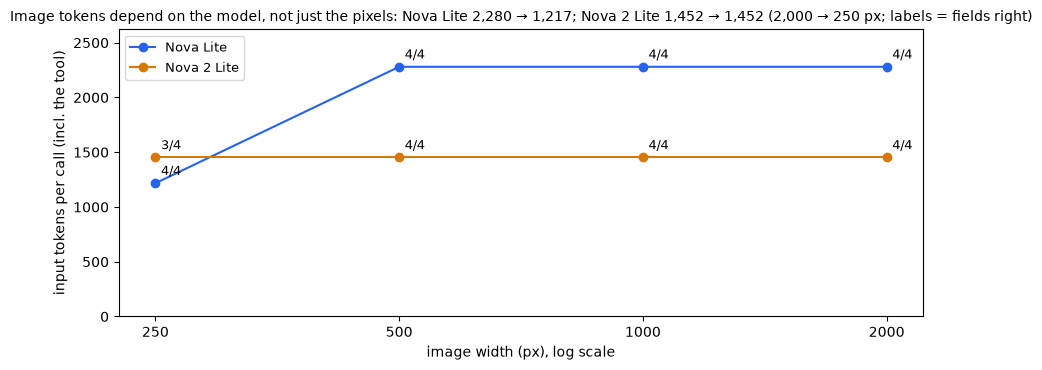

In [23]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 3.8))
for model, color in zip(MODELS, ["#2563eb", "#d97706"]):
    rows = [r for r in IMAGES if r["model"] == m.model_name(model)]
    ax.plot([r["width px"] for r in rows], [r["input tokens"] for r in rows], marker="o", color=color,
            label=m.model_name(model))
    for r in rows:
        ax.annotate(r["fields right"], (r["width px"], r["input tokens"]), xytext=(4, 6), textcoords="offset points",
                    fontsize=9)
ax.set_xscale("log"); ax.minorticks_off(); ax.set_xticks(WIDTHS); ax.set_xticklabels(WIDTHS)
ax.set_ylim(0, 1.15 * max(r["input tokens"] for r in IMAGES))
ax.set_xlabel("image width (px), log scale"); ax.set_ylabel("input tokens per call (incl. the tool)")
ax.legend(fontsize=9)
tok = {(r["model"], r["width px"]): r["input tokens"] for r in IMAGES}
ax.set_title("Image tokens depend on the model, not just the pixels: "
             + "; ".join(f"{n} {tok[(n, 2000)]:,} → {tok[(n, 250)]:,}" for n in ("Nova Lite", "Nova 2 Lite"))
             + " (2,000 → 250 px; labels = fields right)", fontsize=10)
plt.tight_layout(); plt.show()

> **Think about it:** Does each model charge less for a smaller image — and does it still read every field? What is
> the rule you would write into your preprocessing Lambda — a fixed width, or a measured one per model?

<details><summary>More questions</summary>

- The contract costs ≈ 700–1,100 input tokens per call. When is that worth it, and when is "return JSON" +
  validation enough?
- Crop to the region you need, or downscale the whole page — which keeps accuracy better for small handwriting?
</details>

## Cleanup — don't skip this
Deletes the Transcribe jobs and the bucket (audio, transcripts, accepted and quarantined records).
**Run it after Part 2 (console)** — the console demo transcribes the audio file in this bucket.

In [24]:
def our_jobs() -> list[str]:
    """ListTranscriptionJobs has no boto3 paginator: follow NextToken by hand."""
    names, token = [], None
    while True:
        r = transcribe.list_transcription_jobs(JobNameContains="mlaidp2-m02", MaxResults=100,
                                               **({"NextToken": token} if token else {}))
        names += [j["TranscriptionJobName"] for j in r["TranscriptionJobSummaries"]]
        token = r.get("NextToken")
        if not token:
            return names

for job in our_jobs():
    transcribe.delete_transcription_job(TranscriptionJobName=job)
    print(f"  deleted transcription job {job}")
with contextlib.redirect_stdout(io.StringIO()) as said:       # the shared helper prints the bucket name: mask it
    m.empty_and_delete_bucket(BUCKET)
print(m.masked(said.getvalue().rstrip()))
left = our_jobs() + [m.masked(b["Name"]) for b in s3.list_buckets()["Buckets"] if b["Name"].startswith("mlaidp2-m02")]
print("✓ nothing left" if not left else f"✗ still there: {left}")

  deleted transcription job mlaidp2-m02-call-all-1022b42a
  deleted transcription job mlaidp2-m02-call-must-1022b42a


  deleted bucket mlaidp2-m02-123456789012-us-east-1


✓ nothing left
